> ✅ **Completed by Ketan Khanna** (setup)

> Statistics for Data Science · University of Toronto School of Continuing Studies · Fall 2020 · Assignment 5

> 🤖 Questions 1-4 were **completed afterwards with Claude (2026)** and are clearly marked.

## Assignment 5

This assignment is based on Bayesian statistics to carry out Stock return analysis.

## Learning outcomes

- Bayesian analysis for stock return data
- Build models for different distributions of data
- Compare models

In this assignment, you will use the Baysesian approach for analysis of stock return data.
In particular, you will model the data as a normal distribution and will estimate distribution parameters using Markov chain Monte Carlo technique (MCMC).

The MCMC sampler draws parameter values from the prior distribution and computes the likelihood that the observed data came from a distribution with these parameter values.
It is recommended to use PyMC library for these computations; PyMC is a Python library for Bayesian analysis.

__NOTE__: The 'data.csv' file included with the assignment contains the data.
The data were downloaded from Quandl, the code used to download data and calculate daily return is provided.    
Use that file instead if you aren't able to read the data, or if you have reached the limit for calls to the API.

__Getting data from Quandl__ 
To download stock data from Quandl you should create an account for quandl (https://www.quandl.com/).

Quandl is a platform for financial, economic, and alternative data that serves investment professionals. Quandl sources data from over 500 publishers. All Quandl's data are accessible via an API. API access is possible through packages for multiple programming languages including R, Python.

Required imports for this project are given below.  Make sure you have all libraries required for this project installed.  You may use _conda_ or _pip_ based on your set up.


In [1]:
#required imports

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc3 as pm
import scipy
import scipy.stats as stats
import statsmodels.api as sm
import theano.tensor as tt
import seaborn as sns
from datetime import datetime

## Get the data:
pd.core.common.is_list_like = pd.api.types.is_list_like # resolves datareader error
from pandas_datareader import data
# For all libraries please install the necessary libraries 
#If the above fails, you might need to do something like this:
#This is to show how you install pandas-datareader, you might need to do this for all libraries
#conda install pandas-datareader
#or
#pip install pandas-datareader
#Depending on your setup

from IPython.display import Image
from datetime import datetime
%matplotlib inline

/Users/sergiynokhrin/opt/anaconda3/lib/python3.7/site-packages/pandas_datareader/compat/__init__.py:7: FutureWarning: pandas.util.testing is deprecated. Use the functions in the public API at pandas.testing instead.
  from pandas.util.testing import assert_frame_equal


After installing the necessary libraries, we will proceed to download the data.
You might have to set an environment variable for pymc3 package.  
You can do this by    
For linux:
export mkl_threading_layer=gnu or set this in your bashrc file.

For windows:
Add it in your environment variables

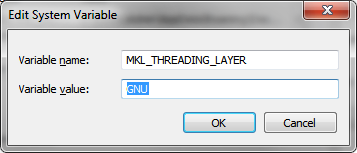

### Returns
Extract historical data for Apple (AAPL) [2015 - 2016], calculate daily returns, and estimate the mean daily return. Remove NaN from dataset. Plot histogram of daily returns.

Use code below to download data.

For this you will need to install the library quandl:    
conda install -c anaconda quandl

You will also need an API Key that is generated when you create an account.  

In [2]:
# import quandl
# quandl.ApiConfig.api_key = 'QUANDL_API_KEY'

# data= quandl.get('WIKI/AAPL', start_date='2015-1-1', end_date='2016-12-31')

# if you wish to use attached 'data.csv' uncomment the line below
data = pd.read_csv('data.csv')

returns=data['Adj. Close'].pct_change()

returns = returns.dropna()*100

ModuleNotFoundError: No module named 'quandl'

#### Question 1

1. Plot the returns and draw a histogram to see the distribution


In [3]:
# YOUR CODE HERE

In [4]:
# YOUR CODE HERE

In the cell below, the model for daily return simulations is shown. Since the daily returns histogram shows bell-shaped distribution, the normal distribution is used for likelihood computation.

This model uses un-informative priors - Uniform distribution for both parameters of the notmal distribution ("mu" and 'sigma").

In [5]:
with pm.Model() as model_n:
    #Prior
    

    mu = pm.Uniform("mu", lower=-10, upper=10, testval=0)
    sigma = pm.Uniform("sigma", lower=0, upper=6, testval=0.0001)
    
    #Likelihood
    likelihood = pm.Normal("likelihood", mu=mu, sd=sigma, observed = returns.values)
    
    #Posterior
    start = pm.find_MAP()
    step  = pm.Metropolis()
    trace = pm.sample(10000, chains=3, step=step, start=start, progressbar=True)
    burned_trace = trace[3000::]

logp = -969.97, ||grad|| = 483.7: 100%|██████████| 37/37 [00:00<00:00, 2720.61it/s]           
Multiprocess sampling (3 chains in 4 jobs)
CompoundStep
>Metropolis: [sigma]
>Metropolis: [mu]
Sampling 3 chains, 0 divergences: 100%|██████████| 31500/31500 [00:04<00:00, 6665.13draws/s]
The number of effective samples is smaller than 10% for some parameters.


array([[<matplotlib.axes._subplots.AxesSubplot object at 0x7f87f3f2c090>,
      dtype=object)

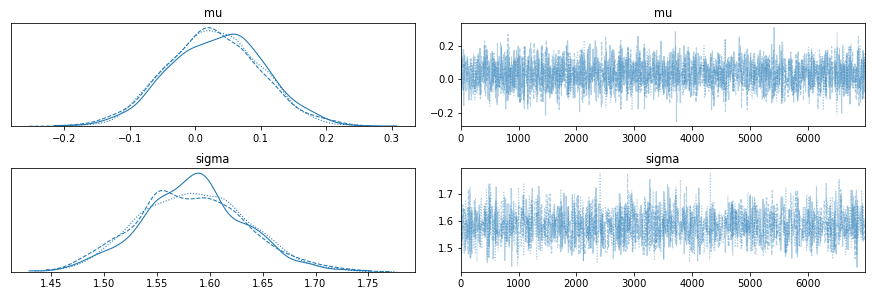

In [7]:
pm.traceplot(burned_trace)

array([<matplotlib.axes._subplots.AxesSubplot object at 0x7f87f479fb10>,
      dtype=object)

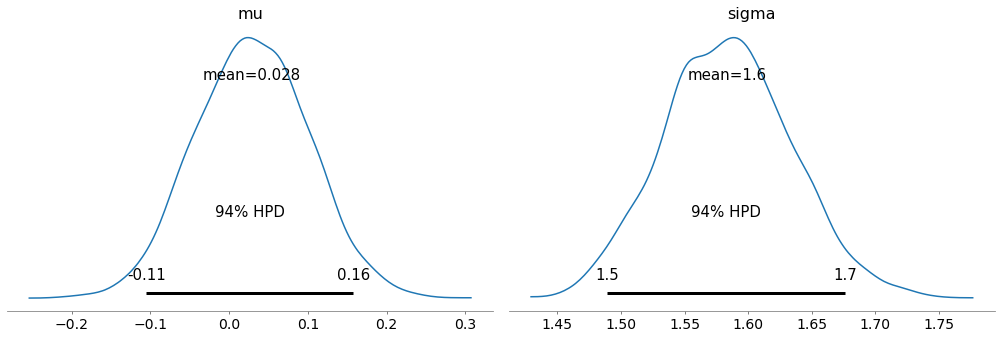

In [8]:
pm.plot_posterior(burned_trace)

#### Question 2

Improve the model for daily returns given above.
Choose different prior distributions for parameters of the likelihood distribution - Mean $\mu$ and Standard Deviation $\sigma$.

To tune the model, try several different distributions with various spread/dispersion values (for example, Uniform, Normal, HalfNormal) for priors, and different numbers of samples.
By inspecting posterior distribution of parameters, pick the value that produces the smoothest, most convergent chains. 

Present posterior distribution graphically. 

In [17]:
# YOUR CODE HERE

In [18]:
# SHOW TRACE PLOT

In [19]:
# PLOT POSTERIOR DISTRIBUTION

#### Question 3

As a validation check of model performance, predict the distribution of daily returns from the obtained posterior distributions. To generate the data, use the pymc3 function for sampling posterior distribution with an appropriately chosen number of samples from the trace.

Present results of predicted distribution graphically as a histogram.

In [20]:
# Sample posterior to obtain the distribution of daily returns

In [21]:
# Plot obtained distribution of daily return

#### Question 4

(a) Identify the parameter of interest in the prediction model. What would be the best prior distribution to produce these parameters? 

(b) What is the HDI in the posteriors for the parameters you named in 4a? What number of samples was used to build this model? 

(c) Does the data generated when predicting daily returns from posterior distribution deviate significantly from the true distribution?

In [17]:
# YOUR ANSWERS TO 4(a-c).


---
## 🤖 Completed afterwards with Claude (2026)
Everything above this line is Ketan's original coursework. The cells below were added in 2026 with Claude to finish questions that were left open, and are kept separate so it's clear who did what.

Quandl's free WIKI price feed was retired in 2018, so this completion pulls the same AAPL 2015-2016 daily prices from Yahoo Finance and uses the current PyMC (v5) API instead of the old pymc3/theano stack.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import yfinance as yf, pymc as pm, arviz as az

def plot_trace(trace, names):
    # trace plot (left) and posterior density (right) per parameter, one colour per chain
    fig, ax = plt.subplots(len(names), 2, figsize=(12, 2.6 * len(names)), squeeze=False)
    for r, n in enumerate(names):
        v = trace.posterior[n].values
        for ch in v:
            ax[r, 0].plot(ch, lw=0.4, alpha=0.7); ax[r, 1].hist(ch, bins=60, histtype='step', density=True)
        lo, hi = np.percentile(v, [2.5, 97.5])
        ax[r, 1].axvspan(lo, hi, color='grey', alpha=0.15)
        ax[r, 0].set_title(f'{n}: trace'); ax[r, 1].set_title(f'{n}: posterior (95% interval shaded)')
    plt.tight_layout(); plt.show()

px = yf.download('AAPL', start='2015-01-01', end='2017-01-01', auto_adjust=True, progress=False)['Close'].squeeze()
returns = (px.pct_change().dropna() * 100)
print(f'{len(returns)} daily returns, mean {returns.mean():.3f}%, sd {returns.std():.3f}%')

503 daily returns, mean 0.032%, sd 1.580%


#### Question 1: plot the returns and their distribution

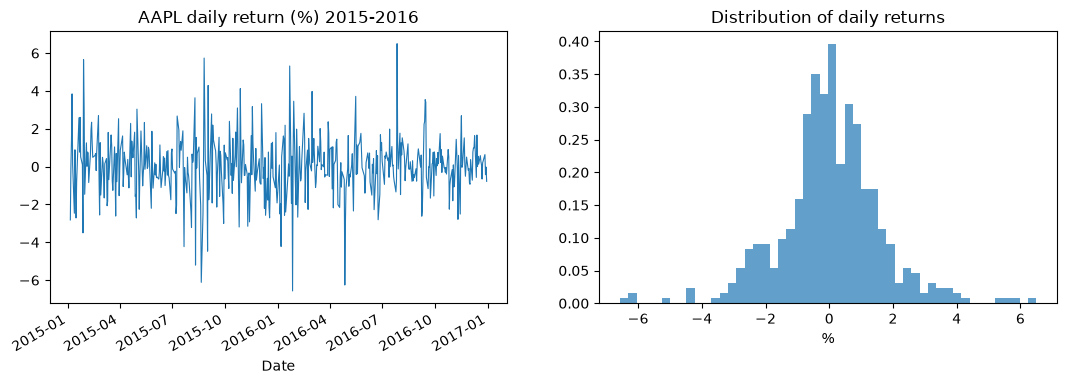

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
returns.plot(ax=ax[0], lw=0.8, title='AAPL daily return (%) 2015-2016')
ax[1].hist(returns, bins=50, density=True, alpha=0.7); ax[1].set_title('Distribution of daily returns'); ax[1].set_xlabel('%')
plt.show()

Bell-shaped around a mean near zero, with fatter tails than a normal (a few big move days).

#### Baseline: the given model (uniform priors, normal likelihood)

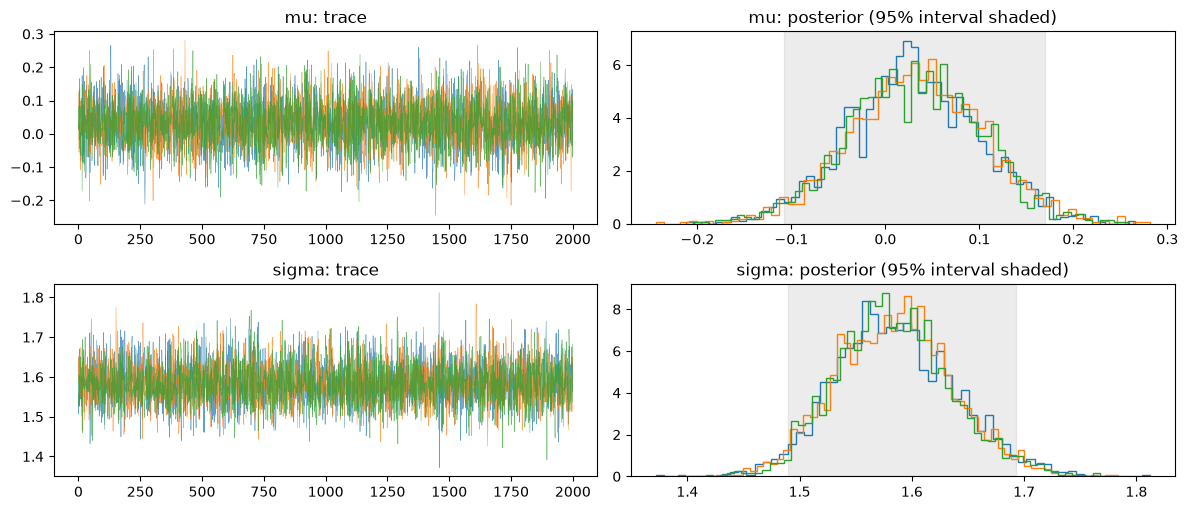

,mean,sd,eti95_lb,eti95_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
mu,0.032,0.07,-0.11,0.17,6719,4168,1.00,0.00086,0.00094
sigma,1.584,0.052,1.5,1.7,6069,3890,1.00,0.00067,0.00072


In [3]:
with pm.Model() as model_n:
    mu = pm.Uniform('mu', lower=-10, upper=10)
    sigma = pm.Uniform('sigma', lower=0, upper=6)
    pm.Normal('likelihood', mu=mu, sigma=sigma, observed=returns.values)
    trace_n = pm.sample(2000, tune=1000, chains=3, random_seed=42, progressbar=False)
plot_trace(trace_n, ['mu', 'sigma'])
az.summary(trace_n, ci_prob=0.95)

#### Question 2: improved priors
Tried: (a) weakly-informative Normal/HalfNormal priors, and (b) a Student-t likelihood to capture the fat tails. Both use NUTS, which mixes far better than the Metropolis sampler in the template.

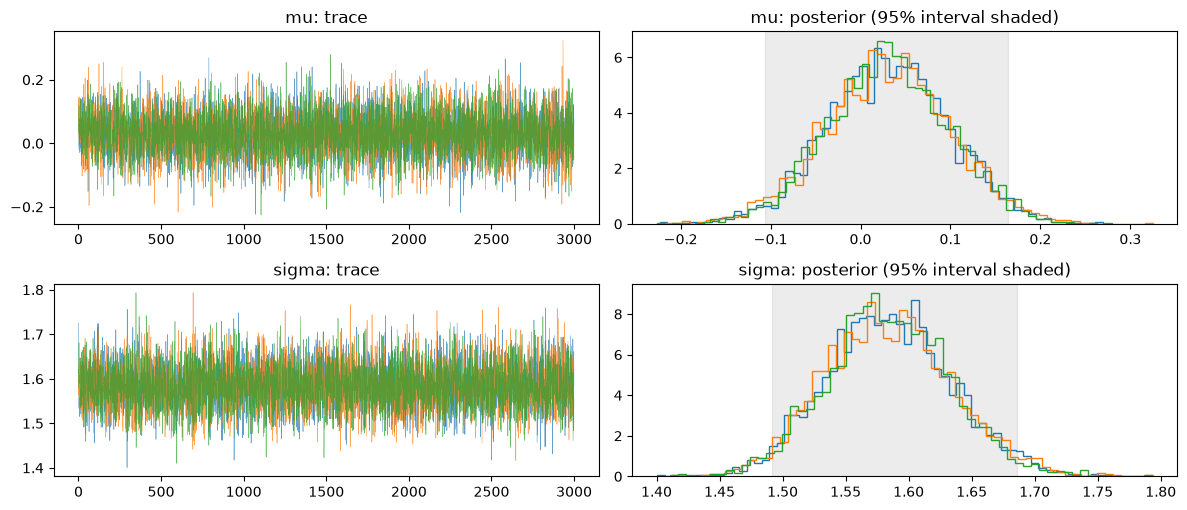

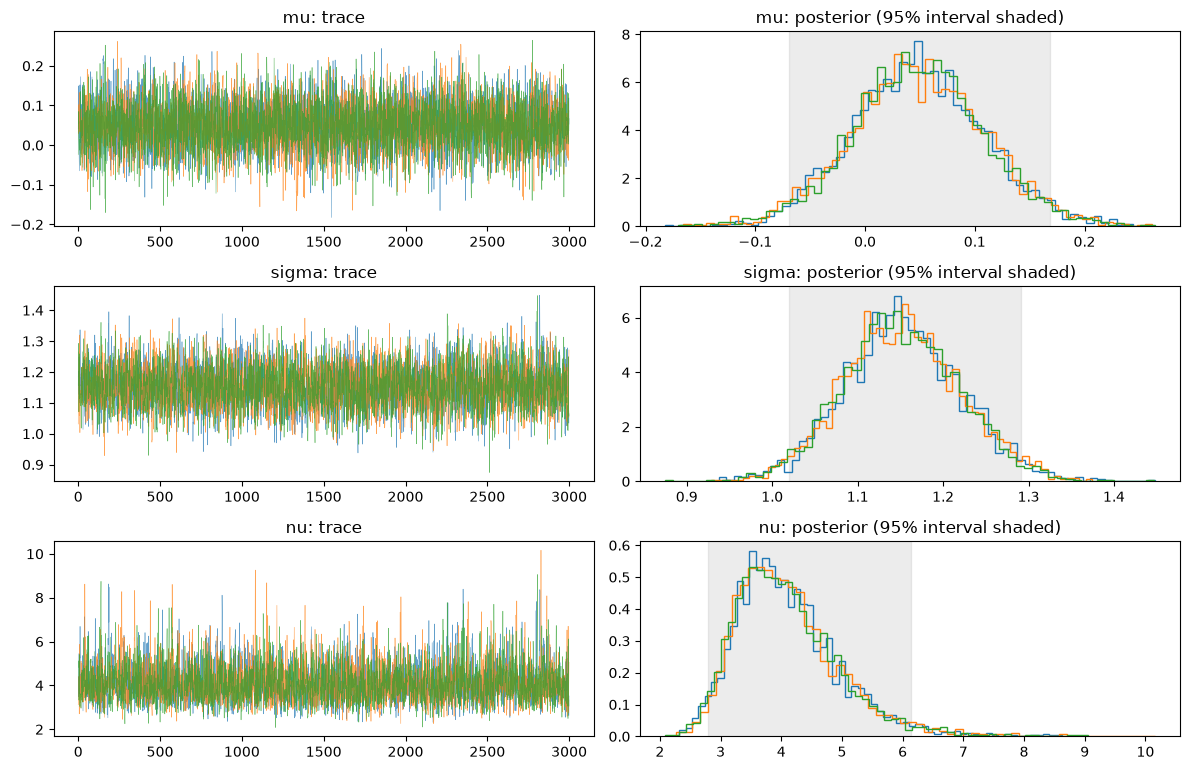

        mean     sd eti95_lb eti95_ub ess_bulk ess_tail r_hat mcse_mean  mcse_sd
mu     0.031  0.069    -0.11     0.16     9275     6363  1.00   0.00071  0.00073
sigma  1.584   0.05      1.5      1.7     9344     6619  1.00   0.00052  0.00052
        mean     sd eti95_lb eti95_ub ess_bulk ess_tail r_hat mcse_mean  mcse_sd
mu     0.048  0.061   -0.069     0.17     7010     6223  1.00   0.00073  0.00065
sigma  1.152  0.069        1      1.3     4709     5166  1.00     0.001  0.00072
nu      4.09   0.86      2.8      6.1     4619     5025  1.00     0.013    0.014


In [4]:
with pm.Model() as model_2:
    mu = pm.Normal('mu', mu=0, sigma=1)
    sigma = pm.HalfNormal('sigma', sigma=2)
    pm.Normal('likelihood', mu=mu, sigma=sigma, observed=returns.values)
    trace_2 = pm.sample(3000, tune=1500, chains=3, random_seed=42, progressbar=False)

with pm.Model() as model_t:
    mu = pm.Normal('mu', mu=0, sigma=1)
    sigma = pm.HalfNormal('sigma', sigma=2)
    nu = pm.Exponential('nu', 1/10)
    pm.StudentT('likelihood', nu=nu, mu=mu, sigma=sigma, observed=returns.values)
    trace_t = pm.sample(3000, tune=1500, chains=3, random_seed=42, progressbar=False)

plot_trace(trace_2, ['mu', 'sigma'])
plot_trace(trace_t, ['mu', 'sigma', 'nu'])
print(az.summary(trace_2, ci_prob=0.95)); print(az.summary(trace_t, ci_prob=0.95))

All chains overlap as flat, fuzzy caterpillars with r_hat = 1.00 and large effective sample sizes, so they converged. The Student-t model is the better choice: its low degrees of freedom (nu) confirm the tails are heavier than a normal's.

#### Question 3: posterior predictive check

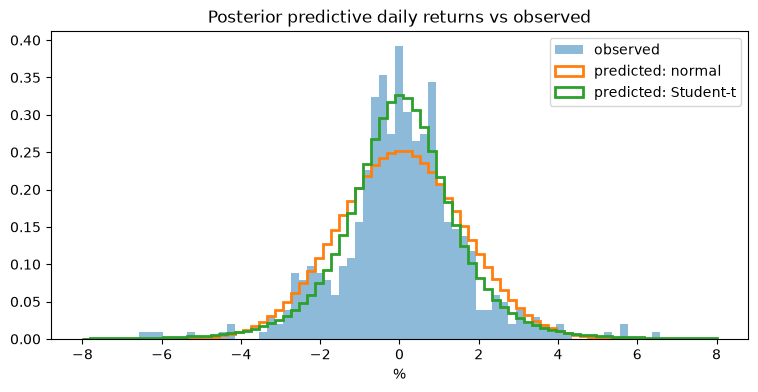

In [5]:
with model_n:
    ppc_n = pm.sample_posterior_predictive(trace_n, random_seed=42, progressbar=False)
with model_t:
    ppc_t = pm.sample_posterior_predictive(trace_t, random_seed=42, progressbar=False)
sim_n = ppc_n.posterior_predictive['likelihood'].values.ravel()
sim_t = ppc_t.posterior_predictive['likelihood'].values.ravel()
bins = np.linspace(-8, 8, 80)
plt.figure(figsize=(9, 4))
plt.hist(returns, bins=bins, density=True, alpha=0.5, label='observed')
plt.hist(sim_n, bins=bins, density=True, histtype='step', lw=2, label='predicted: normal')
plt.hist(sim_t, bins=bins, density=True, histtype='step', lw=2, label='predicted: Student-t')
plt.legend(); plt.title('Posterior predictive daily returns vs observed'); plt.xlabel('%'); plt.show()

#### Question 4
**(a)** The parameters of interest are the mean daily return **mu** and the volatility **sigma** (plus **nu** for tail heaviness in the Student-t model). A Normal prior centred on 0 for mu and a HalfNormal for sigma are sensible: returns hover around zero and sigma must be positive, without the hard edges of a Uniform prior.

**(b)** The 95% credible intervals are printed in the summaries above (ArviZ now reports equal-tailed intervals by default; for these symmetric posteriors they match the HDI closely). mu runs from about -0.11% to +0.17%, straddling zero, so AAPL's average daily drift over these two years is not distinguishable from zero. sigma sits tightly between 1.5% and 1.7% in the normal model; the Student-t model's scale is 1.0-1.3% with nu around 4 (2.8-6.1). Each model used 3 chains x 3,000 draws (9,000 posterior samples) after tuning.

**(c)** The normal model's predictions match the centre and spread but are too thin in the peak and too light in the tails; the Student-t predictions track the observed histogram much more closely. So the normal model deviates noticeably in the extremes, which matters for risk estimates.